# DuckDB

[DuckDB](https://duckdb.org) is an analytical SQL database. It runs in the
notebook with no server: it reads CSV, JSON and Parquet files over HTTP
and keeps tables in memory.

## A first query

`jupyter.sql` runs SQL on an in-memory DuckDB database, written as a
tagged template, and shows the result as a table. The first query loads
DuckDB: its WebAssembly build from a CDN in the apps, its native build,
`@duckdb/node-api`, on Node, Deno and Bun.

In [1]:
await jupyter.sql`select 'Ganymede' as moon, 2634.1 as radius_km, date '1610-01-07' as first_seen, version() as duckdb`;

moonstring,radius_kmnumber,first_seendate,duckdbstring
Ganymede,2634.1,1610-01-07,v1.1.1


## Query a file over HTTP

`jupyter.sql.load` makes a table from a file, guessing its columns' types.
Here, four years of Seattle weather.

In [2]:
await jupyter.sql.load("seattle", "https://raw.githubusercontent.com/vega/vega-datasets/v2.11.0/data/seattle-weather.csv");
await jupyter.sql`describe seattle`;

column_namestring,column_typestring,nullstring,keystring,defaultstring,extrastring
date,DATE,YES,,,
precipitation,DOUBLE,YES,,,
temp_max,DOUBLE,YES,,,
temp_min,DOUBLE,YES,,,
wind,DOUBLE,YES,,,
weather,VARCHAR,YES,,,


In [3]:
await jupyter.sql`
  select year(date) as year,
         round(avg(temp_max), 1) as avg_high,
         round(sum(precipitation)) as rain_mm,
         count(*) filter (where weather = 'sun') as sunny_days
  from seattle
  group by year
  order by year`;

yearinteger,avg_highnumber,rain_mmnumber,sunny_daysinteger
2012,15.3,1226,118
2013,16.1,828,173
2014,17,1233,187
2015,17.4,1139,162


Parquet is read in ranges, so a query fetches only the columns and row
groups it needs. This file holds every New York yellow cab trip of April
2019, 127 MB, but the query below reads two of its columns.

In [4]:
await jupyter.sql`
  select passenger_count as passengers, count(*) as trips
  from 'https://blobs.duckdb.org/data/taxi_2019_04.parquet'
  where passenger_count between 1 and 6
  group by passengers
  order by passengers`;

passengersinteger,tripsinteger
1,5210818
2,1113704
3,317979
4,153369
5,313982
6,186408


## Values from the notebook

A `${value}` in the query is a value, never SQL: whatever it holds, it
can't change the query.

In [5]:
const rainy = 10;
await jupyter.sql`
  select weather, count(*) as days
  from seattle
  where precipitation >= ${rainy}
  group by weather
  order by days desc`;

weatherstring,daysinteger
rain,136
snow,8


Data the notebook already has goes in with `jupyter.sql.load` too, as an
array of objects. Here, the strongest earthquakes of the past week, from
the US Geological Survey.

In [6]:
const feed = await (await fetch("https://earthquake.usgs.gov/earthquakes/feed/v1.0/summary/4.5_week.geojson")).json();
await jupyter.sql.load("quakes", feed.features.map((f: any) => ({
  magnitude: f.properties.mag,
  place: f.properties.place,
  depth_km: f.geometry.coordinates[2],
})));
await jupyter.sql`
  select case when depth_km < 70 then 'shallow' when depth_km < 300 then 'intermediate' else 'deep' end as depth,
         count(*) as quakes,
         max(magnitude) as strongest
  from quakes
  group by depth
  order by min(depth_km)`;

depthstring,quakesinteger,strongestnumber
shallow,84,6.4
intermediate,23,5.4
deep,7,5.1


## Results into charts

A result also has its `rows` as plain objects, ready for a chart. Monthly
rain, from SQL to `jupyter.chart`:

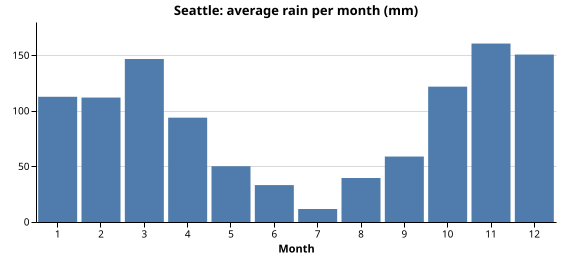

In [7]:
const { rows } = await jupyter.sql`
  select month(date) as month, round(avg(precipitation) * 30, 1) as rain_mm
  from seattle group by month order by month`;
jupyter.chart({
  title: "Seattle: average rain per month (mm)",
  width: 520,
  height: 200,
  data: { values: rows },
  mark: { type: "bar", color: "#4f7cac" },
  encoding: {
    x: { field: "month", type: "ordinal", title: "Month", axis: { labelAngle: 0 } },
    y: { field: "rain_mm", type: "quantitative", title: null },
  },
});

## Clean up

Closing the database frees its memory. Restarting the kernel does the
same.

In [8]:
await jupyter.sql.close();